# Customer Segmentation Analysis

## Project Overview

Customers do not all interact with a business in the same way. Some make frequent purchases, some spend considerably more than others, while others may purchase once and remain inactive for a long period. Understanding these differences can help a business communicate with its customers more effectively instead of applying the same marketing approach to everyone.

This project focuses on segmenting customers of an online retail business based on their purchasing behaviour. The analysis will use transaction history to examine how recently customers purchased, how frequently they placed orders, and how much they spent.

## Objective

The main objective is to identify distinct customer groups using K-Means clustering. The resulting segments will be analysed to understand their purchasing characteristics and recommend suitable marketing actions for each group.

## Approach

The analysis will involve:

* inspecting and cleaning the retail transaction data;
* examining customer purchasing behaviour through descriptive statistics;
* creating Recency, Frequency and Monetary (RFM) features at the customer level;
* standardizing the selected features before clustering;
* using the Elbow Method to determine an appropriate number of clusters;
* applying K-Means clustering to segment the customers;
* visualizing and profiling the resulting customer groups; and
* recommending marketing actions based on the behaviour of each segment.


## Data Loading and Initial Inspection

The dataset was loaded into a pandas DataFrame and reviewed to understand its structure before making any changes. At this stage, I checked the number of records and columns, data types, summary statistics, missing values and duplicate records.

This initial review is useful for identifying data quality issues that could affect the customer-level analysis and clustering later in the project.


In [1]:
#importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans



In [2]:
#importing dataset
online_retail = pd.read_csv('online_retail_II.csv')

In [3]:
online_retail.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:
online_retail.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


In [5]:
online_retail.shape

(1067371, 8)

In [6]:
online_retail.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


In [7]:
online_retail.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [8]:
online_retail.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [9]:
online_retail.duplicated().sum()

np.int64(34335)

In [10]:
missing_values = online_retail.isnull().sum()
missing_values_percentage = (missing_values / len(online_retail)) * 100
print(missing_values_percentage)

Invoice         0.000000
StockCode       0.000000
Description     0.410541
Quantity        0.000000
InvoiceDate     0.000000
Price           0.000000
Customer ID    22.766873
Country         0.000000
dtype: float64


In [11]:
online_retail.rename(
    columns={'Customer ID': 'CustomerID'},
    inplace=True
)

In [12]:
online_retail.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'CustomerID', 'Country'],
      dtype='object')

In [13]:
online_retail[
    online_retail.duplicated(keep=False)
].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [14]:
online_retail[
    online_retail['Price'] <= 0
].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom


In [15]:
online_retail[
    online_retail['Quantity'] < 0
].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [16]:
online_retail[
    online_retail['Quantity'] < 0
].shape[0]

22950

In [17]:
online_retail[
    online_retail['Price'] <= 0
].shape[0]

6207

In [18]:
online_retail[
    online_retail['Invoice'].astype(str).str.startswith('C')
].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


## Initial Data Quality Findings

The initial checks revealed a few issues that need to be addressed before building the customer segments. There are 34,335 duplicated records, which could cause some transactions to be counted more than once.

I also found 22,950 records with negative quantities. A closer look at these rows showed that many of the corresponding invoice numbers begin with "C", indicating cancelled or returned transactions rather than new purchases.

There are also 6,207 records where the price is zero or negative. Some of these rows contain descriptions such as "lost", "damages" and "short", which suggests that they are stock adjustments rather than normal customer sales.

Since the segmentation is intended to reflect actual purchasing behaviour, these records will be excluded before the customer-level features are created.

## Data Cleaning

Before moving to the customer level analysis, I cleaned the transaction data so that the values used for segmentation represent actual purchases as closely as possible. The cleaning focused on duplicate records, unidentified customers, cancelled transactions, invalid quantities and prices, and the invoice date format.

In [19]:
online_retail_2 = online_retail.copy()

In [20]:
online_retail_2 = online_retail_2.drop_duplicates()

In [21]:
online_retail_2.duplicated().sum()

np.int64(0)

In [22]:
online_retail_2.shape

(1033036, 8)

In [23]:
online_retail_2 = online_retail_2.dropna(subset=['CustomerID'])

In [24]:
online_retail_2['CustomerID'].isnull().sum()

np.int64(0)

In [25]:
online_retail_2 = online_retail_2[
    ~online_retail_2['Invoice'].astype(str).str.startswith('C')
]

In [26]:
online_retail_2[
    online_retail_2['Invoice'].astype(str).str.startswith('C')
].shape[0]

0

In [27]:
online_retail_2 = online_retail_2[
    online_retail_2['Quantity'] > 0
]

In [28]:
online_retail_2[
   online_retail_2['Quantity'] <= 0
].shape[0]

0

In [29]:
online_retail_2 = online_retail_2[
    online_retail_2['Price'] > 0
]

In [30]:
online_retail_2[
   online_retail_2['Price'] <= 0
].shape[0]

0

In [31]:
online_retail_2['InvoiceDate'] = pd.to_datetime(
    online_retail_2['InvoiceDate']
)

In [32]:
online_retail_2['InvoiceDate'].dtype

dtype('<M8[ns]')

In [33]:
online_retail_2['CustomerID'] = online_retail_2['CustomerID'].astype(int)

In [34]:
online_retail_2['CustomerID'].dtype

dtype('int64')

In [35]:
online_retail_2.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


In [36]:
online_retail_2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 779425 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      779425 non-null  object        
 1   StockCode    779425 non-null  object        
 2   Description  779425 non-null  object        
 3   Quantity     779425 non-null  int64         
 4   InvoiceDate  779425 non-null  datetime64[ns]
 5   Price        779425 non-null  float64       
 6   CustomerID   779425 non-null  int64         
 7   Country      779425 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(4)
memory usage: 53.5+ MB


In [37]:
online_retail_2.isnull().sum()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
CustomerID     0
Country        0
dtype: int64

In [38]:
online_retail_2.describe()

,Quantity,InvoiceDate,Price,CustomerID
count,779425.000000,779425,779425.000000,779425.000000
mean,13.489370,2011-01-03 01:44:42.593475584,3.218488,15320.360461
min,1.000000,2009-12-01 07:45:00,0.001000,12346.000000
25%,2.000000,2010-07-02 14:39:00,1.250000,13971.000000
50%,6.000000,2010-12-02 14:09:00,1.950000,15247.000000
75%,12.000000,2011-08-01 13:44:00,3.750000,16794.000000
max,80995.000000,2011-12-09 12:50:00,10953.500000,18287.000000
std,145.855814,NaN,29.676140,1695.692775


In [39]:
online_retail_2.shape

(779425, 8)


### Cleaning Summary

After cleaning, 779,425 transaction-line records remain. I removed exact
duplicates, rows without customer IDs, cancelled invoices, and rows with
non-positive quantities or prices.

I also converted InvoiceDate to datetime and CustomerID to an integer.
The remaining records meet the cleaning rules used for this project, although
unusual positive transactions may still remain.

 

## Customer Purchase Behaviour

With the transaction data cleaned, the next step is to move from individual product records towards customer-level behaviour.

A total value will first be calculated for each transaction line using the quantity purchased and the unit price. This will later allow me to measure how much each customer has spent, how often they purchased and how recently they were active.

In [40]:
# Calculate the value of each transaction line
online_retail_2['TotalPrice'] = (
    online_retail_2['Quantity'] * online_retail_2['Price']
)

In [41]:
online_retail_2[
    ['Quantity', 'Price', 'TotalPrice']
].head()

,Quantity,Price,TotalPrice
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


In [42]:
online_retail_2['TotalPrice'].describe()

count    779425.000000
mean         22.291823
std         227.427075
min           0.001000
25%           4.950000
50%          12.480000
75%          19.800000
max      168469.600000
Name: TotalPrice, dtype: float64

In [43]:
# Number of unique customers in the cleaned dataset
online_retail_2['CustomerID'].nunique()

5878

In [44]:
# Count separate orders made by each customer
purchase_frequency = (
    online_retail_2
    .groupby('CustomerID')['Invoice']
    .nunique()
)

purchase_frequency.head()

CustomerID
12346    12
12347     8
12348     5
12349     4
12350     1
Name: Invoice, dtype: int64

In [45]:
# Total amount spent on each order
order_value = (
    online_retail_2
    .groupby(['CustomerID', 'Invoice'])['TotalPrice']
    .sum()
    .reset_index()
)

order_value.head()

,CustomerID,Invoice,TotalPrice
0,12346,491725,45.0
1,12346,491742,22.5
2,12346,491744,22.5
3,12346,492718,22.5
4,12346,492722,1.0


In [46]:
# Average order value for each customer
average_purchase_value = (
    order_value
    .groupby('CustomerID')['TotalPrice']
    .mean()
)

average_purchase_value.head()

CustomerID
12346    6463.038333
12347     615.191250
12348     403.880000
12349    1107.172500
12350     334.400000
Name: TotalPrice, dtype: float64

In [47]:
# Total recorded spending for each customer
customer_value = (
    online_retail_2
    .groupby('CustomerID')['TotalPrice']
    .sum()
)

customer_value.head()

CustomerID
12346    77556.46
12347     4921.53
12348     2019.40
12349     4428.69
12350      334.40
Name: TotalPrice, dtype: float64


## Historical Customer Value

I calculated each customer's total recorded spending during the dataset period.
This is also the Monetary feature used in the RFM analysis.

For the customer lifetime value requirement, I used observed spending as a
historical customer-value proxy. It is not a complete lifetime value estimate,
because purchases outside the dataset period are unknown. It also does not
predict future spending or account for profit margins and refunds.

## Initial Customer Purchase Summary

The cleaned dataset contains 5,878 unique customers. Purchase frequency was calculated using the number of distinct invoices rather than the number of transaction rows, since a single order may contain several products.

I also calculated the total value of each order and used this to obtain the average purchase value for each customer. Total spending was calculated separately to represent the value contributed by each customer over the period covered by the dataset.

The transaction values vary considerably. While the median transaction-line value is 12.48, the maximum is much higher at 168,469.60. This suggests that spending is not evenly distributed across the transactions, so the customer-level values will be examined further before clustering.

In [48]:
# Use the day after the last transaction as the reference date
analysis_date = online_retail_2['InvoiceDate'].max() + pd.Timedelta(days=1)

analysis_date

Timestamp('2011-12-10 12:50:00')

In [49]:
# Most recent purchase date for each customer
last_purchase = (
    online_retail_2
    .groupby('CustomerID')['InvoiceDate']
    .max()
)

last_purchase.head()

CustomerID
12346   2011-01-18 10:01:00
12347   2011-12-07 15:52:00
12348   2011-09-25 13:13:00
12349   2011-11-21 09:51:00
12350   2011-02-02 16:01:00
Name: InvoiceDate, dtype: datetime64[ns]

In [50]:
# Number of days since each customer's most recent purchase
recency = (analysis_date - last_purchase).dt.days

recency.head()

CustomerID
12346    326
12347      2
12348     75
12349     19
12350    310
Name: InvoiceDate, dtype: int64

In [51]:
rfm = pd.DataFrame({
    'Recency': recency,
    'Frequency': purchase_frequency,
    'Monetary': customer_value
})

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,12,77556.46
12347,2,8,4921.53
12348,75,5,2019.40
12349,19,4,4428.69
12350,310,1,334.40


In [52]:
rfm = rfm.reset_index()

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346,326,12,77556.46
1,12347,2,8,4921.53
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40


In [53]:
rfm['AveragePurchaseValue'] = (
    rfm['CustomerID'].map(average_purchase_value)
)

In [54]:
rfm.head()

,CustomerID,Recency,Frequency,Monetary,AveragePurchaseValue
0,12346,326,12,77556.46,6463.038333
1,12347,2,8,4921.53,615.191250
2,12348,75,5,2019.40,403.880000
3,12349,19,4,4428.69,1107.172500
4,12350,310,1,334.40,334.400000


In [55]:
rfm.shape

(5878, 5)

In [56]:
rfm.isnull().sum()

CustomerID              0
Recency                 0
Frequency               0
Monetary                0
AveragePurchaseValue    0
dtype: int64

In [57]:
rfm[['Recency', 'Frequency', 'Monetary', 'AveragePurchaseValue']
].describe()

,Recency,Frequency,Monetary,AveragePurchaseValue
count,5878.000000,5878.000000,5878.000000,5878.000000
mean,201.331916,6.289384,2955.904095,385.180841
std,209.338707,13.009406,14440.852688,1214.286459
min,1.000000,1.000000,2.950000,2.950000
25%,26.000000,1.000000,342.280000,176.682500
50%,96.000000,3.000000,867.740000,279.242679
75%,380.000000,7.000000,2248.305000,414.902458
max,739.000000,398.000000,580987.040000,84236.250000


### Observation

The customer-level statistics show noticeable differences in purchasing behaviour. The median customer made 3 separate purchases, while the average is about 6 purchases. A small number of customers are considerably more active, with the highest purchase frequency reaching 398 orders.

Customer spending also varies widely. The median total spending is 867.74, compared with an average of 2,955.90, while the highest recorded customer value is 580,987.04. This large gap between the typical customer and the highest values suggests that the Frequency and Monetary variables are strongly skewed.

Recency also varies considerably. Half of the customers made their most recent purchase within 96 days of the reference date, while some customers had not purchased for much longer periods.

Because these differences may influence a distance-based method such as K-Means, the distributions of the RFM variables will be examined before clustering.

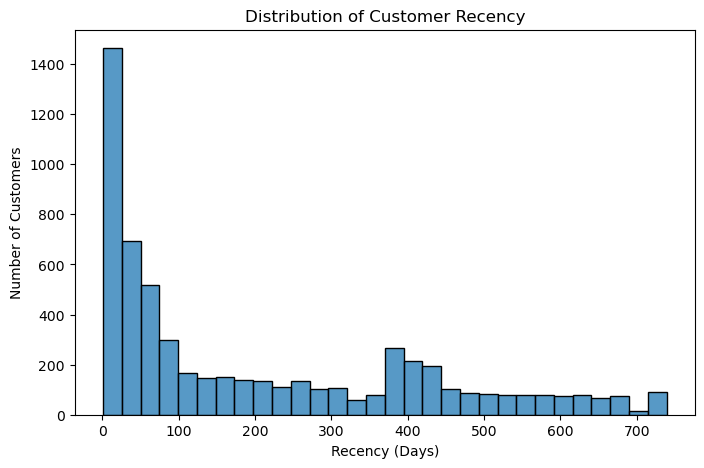

In [58]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=rfm,
    x='Recency',
    bins=30
)

plt.title('Distribution of Customer Recency')
plt.xlabel('Recency (Days)')
plt.ylabel('Number of Customers')

plt.show()

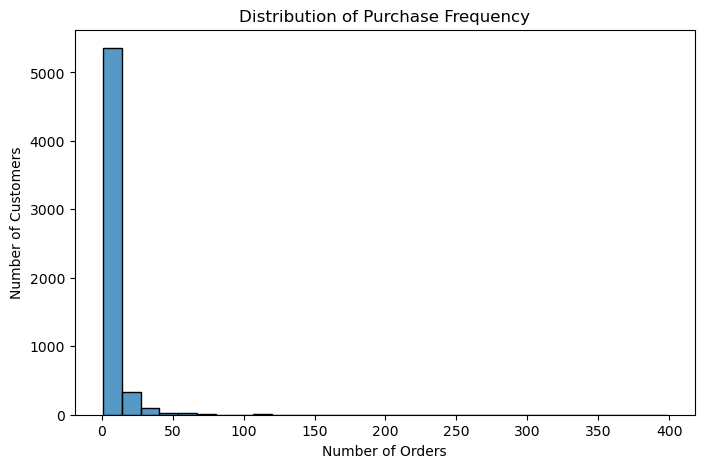

In [59]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=rfm,
    x='Frequency',
    bins=30
)

plt.title('Distribution of Purchase Frequency')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers')

plt.show()

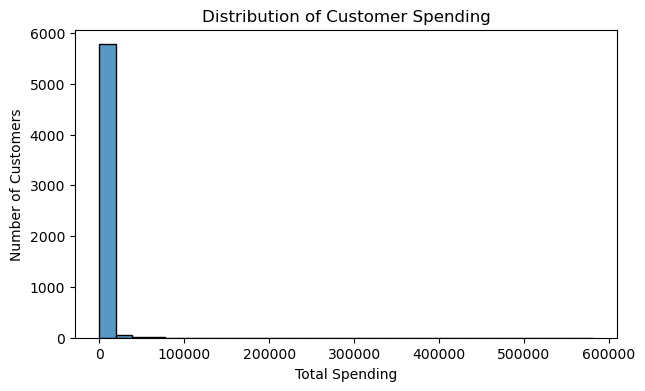

In [60]:
plt.figure(figsize=(7, 4))

sns.histplot(
    data=rfm,
    x='Monetary',
    bins=30
)

plt.title('Distribution of Customer Spending')
plt.xlabel('Total Spending')
plt.ylabel('Number of Customers')

plt.show()


## Feature Selection

I selected three customer-level features:

- Recency: days since the customer's most recent purchase.
- Frequency: number of distinct orders during the dataset period.
- Monetary: total recorded spending during the dataset period.

I kept Average Purchase Value for descriptive analysis but did not include it
as a fourth clustering feature.

In [61]:
# Keep only the RFM features that will be used for clustering
rfm_log = rfm[
    ['Recency', 'Frequency', 'Monetary']
].copy()

### Preparing the Features for Clustering

Frequency and Monetary have much higher means than medians, with a few very
large values. I used log1p on the three RFM features to reduce the influence
of large values.

I then applied StandardScaler so that differences in measurement units would
not dominate the clustering. The original RFM values were retained for
interpreting the customer segments.

In [62]:
# Reduce the effect of very large values
rfm_log['Recency'] = np.log1p(rfm_log['Recency'])
rfm_log['Frequency'] = np.log1p(rfm_log['Frequency'])
rfm_log['Monetary'] = np.log1p(rfm_log['Monetary'])

In [63]:
rfm_log.head()

,Recency,Frequency,Monetary
0,5.789960,2.564949,11.258774
1,1.098612,2.197225,8.501578
2,4.330733,1.791759,7.611051
3,2.995732,1.609438,8.396085
4,5.739793,0.693147,5.815324


In [64]:
# Standardize the three features used for clustering
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

In [65]:
rfm_scaled[:5]

array([[ 0.85670058,  1.25449595,  3.20621937],
       [-2.15197903,  0.80016603,  1.21599349],
       [-0.07913835,  0.29920733,  0.57318471],
       [-0.93530818,  0.07394609,  1.13984551],
       [ 0.82452706, -1.05814595, -0.72302406]])

In [66]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

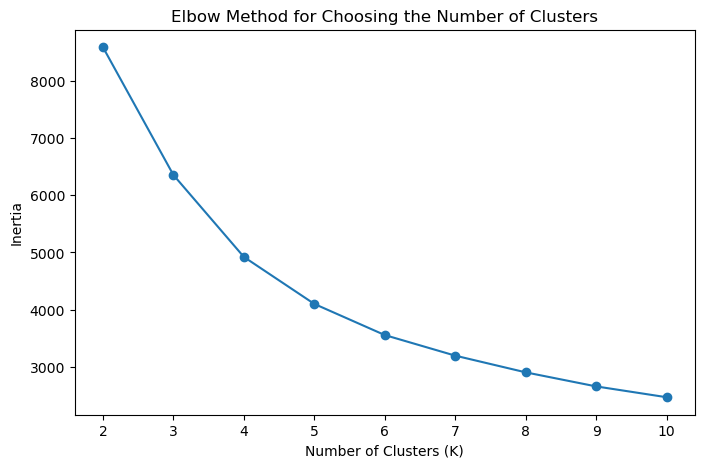

In [67]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.title('Elbow Method for Choosing the Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')

plt.show()

### Observation
The inertia decreases noticeably as the number of clusters increases from 2 to 4. After K = 4, the reduction becomes more gradual. Based on this pattern, I used 4 clusters for the final K-Means model.

In [68]:
# Build the final K-Means model using 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(rfm_scaled)

In [69]:
# Add each customer's cluster number to the RFM table
rfm['Cluster'] = cluster_labels

In [70]:
rfm.head()

,CustomerID,Recency,Frequency,Monetary,AveragePurchaseValue,Cluster
0,12346,326,12,77556.46,6463.038333,2
1,12347,2,8,4921.53,615.191250,2
2,12348,75,5,2019.40,403.880000,3
3,12349,19,4,4428.69,1107.172500,1
4,12350,310,1,334.40,334.400000,0


In [71]:
rfm['Cluster'].value_counts().sort_index()

Cluster
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64

In [72]:
# Compare the average behaviour of customers in each cluster
cluster_profile = (
    rfm
    .groupby('Cluster')[
        ['Recency', 'Frequency', 'Monetary', 'AveragePurchaseValue']
    ]
    .mean()
    .round(2)
)

cluster_profile

,Recency,Frequency,Monetary,AveragePurchaseValue
Cluster,,,,
0,394.95,1.38,317.08,249.86
1,28.30,3.05,857.49,316.38
2,27.71,19.28,10731.16,565.24
3,230.07,5.06,1948.50,479.52


In [73]:
cluster_size = (
    rfm
    .groupby('Cluster')['CustomerID']
    .count()
)

cluster_size

Cluster
0    1973
1    1250
2    1196
3    1459
Name: CustomerID, dtype: int64

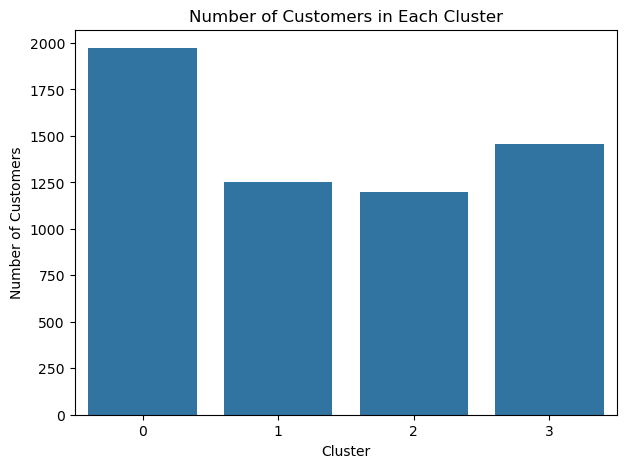

In [74]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=rfm,
    x='Cluster'
)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')

plt.show()

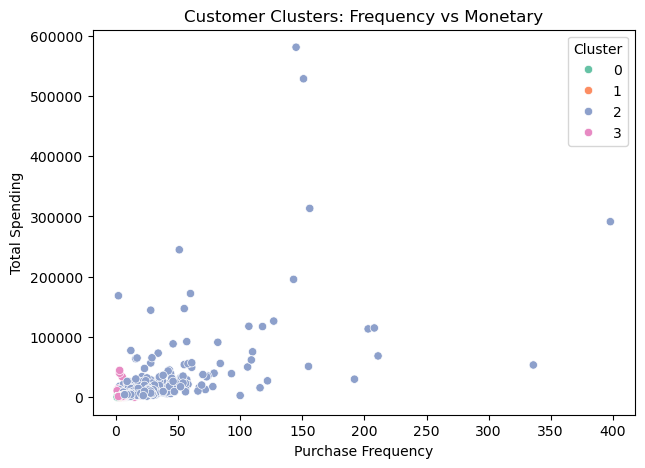

In [75]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='Set2'
)

plt.title('Customer Clusters: Frequency vs Monetary')
plt.xlabel('Purchase Frequency')
plt.ylabel('Total Spending')

plt.show()

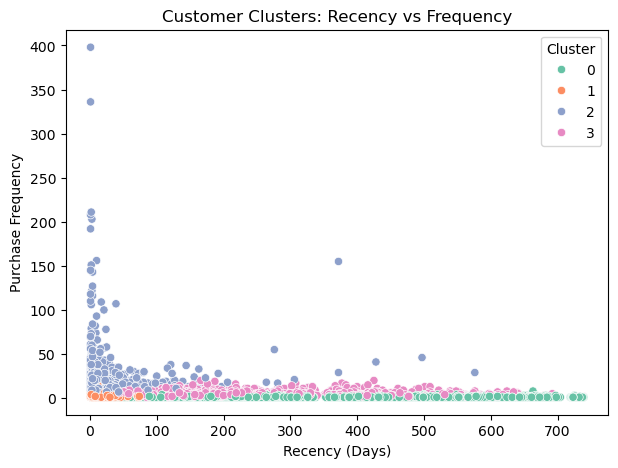

In [76]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Cluster',
    palette='Set2'
)

plt.title('Customer Clusters: Recency vs Frequency')
plt.xlabel('Recency (Days)')
plt.ylabel('Purchase Frequency')

plt.show()

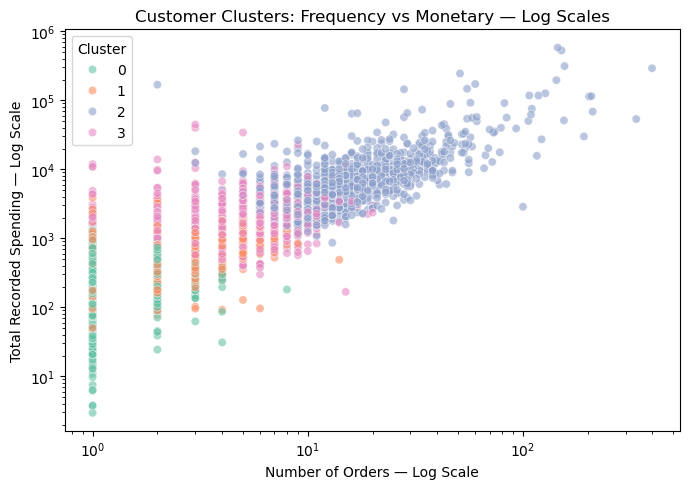

In [77]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='Set2',
    alpha=0.6
)

plt.xscale('log')
plt.yscale('log')

plt.title('Customer Clusters: Frequency vs Monetary — Log Scales')
plt.xlabel('Number of Orders — Log Scale')
plt.ylabel('Total Recorded Spending — Log Scale')

plt.tight_layout()
plt.show()

The log scales make customers with lower order counts and spending easier
to distinguish, without removing the highest-value customers from the plot.

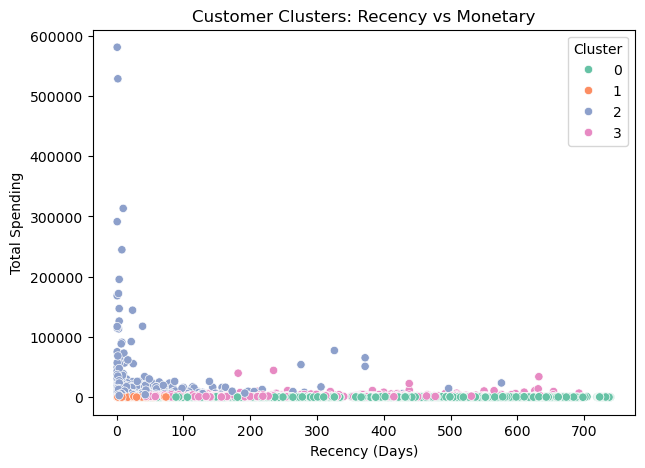

In [78]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='Set2'
)

plt.title('Customer Clusters: Recency vs Monetary')
plt.xlabel('Recency (Days)')
plt.ylabel('Total Spending')

plt.show()

### Observation

Cluster 0 contains the largest number of customers, with 1,973 customers, while Cluster 2 is the smallest group with 1,196 customers. The remaining customers are distributed between Cluster 1 with 1,250 customers and Cluster 3 with 1,459 customers.

Although Cluster 2 has the fewest customers, its customer profile shows that this group has the highest purchase frequency and spending. This suggests that the size of a customer segment alone does not determine its value to the business.

In [79]:
# Give each cluster a name based on its purchasing behaviour
segment_names = {
    0: 'Inactive Low-Value',
    1: 'Recent Occasional',
    2: 'High-Value Frequent',
    3: 'Established Less-Recent'
}

rfm['Segment'] = rfm['Cluster'].map(segment_names)

In [80]:
rfm.head()

,CustomerID,Recency,Frequency,Monetary,AveragePurchaseValue,Cluster,Segment
0,12346,326,12,77556.46,6463.038333,2,High-Value Frequent
1,12347,2,8,4921.53,615.191250,2,High-Value Frequent
2,12348,75,5,2019.40,403.880000,3,Established Less-Recent
3,12349,19,4,4428.69,1107.172500,1,Recent Occasional
4,12350,310,1,334.40,334.400000,0,Inactive Low-Value


## Customer Segment Insights and Marketing Actions

The four clusters show that customers differ not only in how much they spend, but also in how recently and how frequently they purchase.

**Cluster 0 – Inactive Low-Value Customers:**  
Customers in this segment have the longest average recency, the lowest purchase frequency and the lowest total spending. Low-cost re-engagement campaigns or limited comeback offers may be more appropriate for this group than expensive retention campaigns.

**Cluster 1 – Recent Occasional Customers:**  
These customers have purchased recently but have only made a few purchases on average. Follow-up recommendations and repeat-purchase incentives could help encourage them to become more regular customers.

**Cluster 2 – High-Value Frequent Customers:**  
This segment purchases recently and frequently and contributes the highest average spending by a wide margin. The focus for this group should be retention through loyalty rewards, personalised recommendations and early access to products rather than relying heavily on discounts.

**Cluster 3 – Established Less-Recent Customers:**  
Customers in this segment have historically purchased more frequently and spent more than the lower-value groups, but their purchases are less recent. Targeted win-back campaigns may help reactivate customers who previously showed stronger purchasing behaviour.

In [81]:
# Bring the cluster size and segment name into the profile table
cluster_summary = cluster_profile.copy()

cluster_summary['Customers'] = (
    rfm['Cluster'].value_counts().sort_index()
)

cluster_summary['Segment'] = cluster_summary.index.map(segment_names)

cluster_summary = cluster_summary.reset_index()

cluster_summary

,Cluster,Recency,Frequency,Monetary,AveragePurchaseValue,Customers,Segment
0,0,394.95,1.38,317.08,249.86,1973,Inactive Low-Value
1,1,28.30,3.05,857.49,316.38,1250,Recent Occasional
2,2,27.71,19.28,10731.16,565.24,1196,High-Value Frequent
3,3,230.07,5.06,1948.50,479.52,1459,Established Less-Recent


## Customer Segment Summary

### Observation:
The clustering divided the 5,878 customers into four groups with different purchasing patterns. The largest segment is the Inactive Low-Value group with 1,973 customers, while the High-Value Frequent segment has 1,196 customers. Although this is the smallest segment, its average spending and purchase frequency are substantially higher than those of the other groups. The results show that customer count alone does not describe the value or behaviour of a segment.



In [83]:
cluster_summary = cluster_summary[
    [
        'Cluster',
        'Segment',
        'Customers',
        'Recency',
        'Frequency',
        'Monetary',
        'AveragePurchaseValue'
    ]
]

cluster_summary

,Cluster,Segment,Customers,Recency,Frequency,Monetary,AveragePurchaseValue
0,0,Inactive Low-Value,1973,394.95,1.38,317.08,249.86
1,1,Recent Occasional,1250,28.30,3.05,857.49,316.38
2,2,High-Value Frequent,1196,27.71,19.28,10731.16,565.24
3,3,Established Less-Recent,1459,230.07,5.06,1948.50,479.52


## Conclusion

This analysis showed that the online retail customer base is made up of customers with noticeably different purchasing behaviours. After cleaning the transaction data, customer activity was summarised using Recency, Frequency and Monetary values to capture how recently customers purchased, how often they ordered and how much they spent.

The RFM variables showed considerable variation across customers, particularly in purchase frequency and total spending. To prepare the data for clustering, the variables were log-transformed and standardized before applying K-Means. The Elbow Method indicated that four clusters provided a suitable balance for the analysis.

The resulting clusters represented four different customer profiles: Inactive Low-Value customers, Recent Occasional customers, High-Value Frequent customers, and Established Less-Recent customers. The differences between these groups suggest that a single marketing approach would not address all customers in the same way.

The segmentation can therefore be used as a starting point for more targeted marketing. Less active customers can be approached with re-engagement campaigns, recent occasional customers can be encouraged to purchase more frequently, high-value frequent customers can be supported through retention and loyalty initiatives, and previously active but less-recent customers can be targeted with win-back campaigns.